# Assignment 1 — training pipeline

## 1. Load the data
The file uses semicolons as separators. I also clean the column names, because one of them has a hidden tab at the end.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/data.csv", sep=";", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

print(df.shape)
df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Build the target
I removed the 794 "Enrolled" students. Their final outcome is unknown. The target is 1 = dropout, 0 = graduate (3,630 students, 39% dropouts).

In [2]:
# Remove students still enrolled (their final outcome is unknown)
df = df[df["Target"] != "Enrolled"].copy()

# Build the target: 1 = dropout, 0 = graduate
df["dropout"] = (df["Target"] == "Dropout").astype(int)
df = df.drop(columns=["Target"])

print(df.shape)
print(df["dropout"].value_counts())
print("Share of dropouts:", df["dropout"].mean())

(3630, 37)
dropout
0    2209
1    1421
Name: count, dtype: int64
Share of dropouts: 0.39146005509641874


## 3. Remove 2nd-semester columns (leakage)
The model runs at the end of the 1st semester, so 2nd-semester results don't exist yet at that point. Using them would be leakage.

In [3]:
# Remove 2nd-semester columns: the model runs at the end of the
# 1st semester, so this information doesn't exist yet (leakage)
second_sem_cols = [col for col in df.columns if "2nd sem" in col]
print(second_sem_cols)

df = df.drop(columns=second_sem_cols)
print(df.shape)

['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
(3630, 31)


## 4. Set aside the fee columns
Students with unpaid fees dropped out 94% of the time, and debtors 76%. The data doesn't say when these columns were recorded, so they might reflect dropping out instead of predicting it. I left them out of the main model and keep them aside for one ablation check that I will do later on.

In [4]:
# Dropout rate for each value of the two financial columns
print(df.groupby("Tuition fees up to date")["dropout"].mean())
print(df.groupby("Debtor")["dropout"].mean())

Tuition fees up to date
0    0.940329
1    0.306616
Name: dropout, dtype: float64
Debtor
0    0.344731
1    0.755448
Name: dropout, dtype: float64


In [5]:
# Fee columns: recording time unknown, possible leakage.
# Left out of the main model; kept aside for one ablation check later.
fee_cols = ["Debtor", "Tuition fees up to date"]
fees = df[fee_cols].copy()

df = df.drop(columns=fee_cols)
print(df.shape)

(3630, 29)


## 5. Explore the 1st-semester columns
152 students enrolled in 0 courses (51% dropped out), and most students have 0 credited courses. A grade of 0 often means "no grade", not a bad grade.

In [6]:
# Look at the 1st-semester columns before engineering anything
sem1_cols = [col for col in df.columns if "1st sem" in col]
print(df[sem1_cols].describe().round(2))

# How many students were enrolled in 0 units in the 1st semester?
zero_enrolled = df["Curricular units 1st sem (enrolled)"] == 0
print("Students with 0 units enrolled:", zero_enrolled.sum())
print("Their dropout rate:", df.loc[zero_enrolled, "dropout"].mean().round(2))

       Curricular units 1st sem (credited)  \
count                              3630.00   
mean                                  0.75   
std                                   2.48   
min                                   0.00   
25%                                   0.00   
50%                                   0.00   
75%                                   0.00   
max                                  20.00   

       Curricular units 1st sem (enrolled)  \
count                              3630.00   
mean                                  6.34   
std                                   2.57   
min                                   0.00   
25%                                   5.00   
50%                                   6.00   
75%                                   7.00   
max                                  26.00   

       Curricular units 1st sem (evaluations)  \
count                                 3630.00   
mean                                     8.07   
std                    

## 6. Engineer 1st-semester features
- `pass_rate_1st_sem`: share of enrolled courses passed.
- `no_units_1st_sem`: flags students who took no courses.
- `passed_nothing_1st_sem`: flags students who passed nothing (88% dropped out vs 29%), so the model can tell "no grade" from "low grade".
- `has_credits`: flags students with credits from previous studies; the yes/no matters more than the count.

In [7]:
enrolled = df["Curricular units 1st sem (enrolled)"]
approved = df["Curricular units 1st sem (approved)"]
credited = df["Curricular units 1st sem (credited)"]

# Share of enrolled courses passed (0 if the student enrolled in nothing)
df["pass_rate_1st_sem"] = np.where(enrolled > 0, approved / enrolled.clip(lower=1), 0)

# Yes/no flags (1 = yes, 0 = no)
df["no_units_1st_sem"] = (enrolled == 0).astype(int)
df["passed_nothing_1st_sem"] = (approved == 0).astype(int)
df["has_credits"] = (credited > 0).astype(int)

new_cols = ["pass_rate_1st_sem", "no_units_1st_sem", "passed_nothing_1st_sem", "has_credits"]
print(df.groupby("passed_nothing_1st_sem")["dropout"].mean().round(2))
df[new_cols].describe().round(2)

passed_nothing_1st_sem
0    0.29
1    0.88
Name: dropout, dtype: float64


,pass_rate_1st_sem,no_units_1st_sem,passed_nothing_1st_sem,has_credits
count,3630.00,3630.00,3630.00,3630.00
mean,0.70,0.04,0.18,0.13
std,0.38,0.20,0.38,0.34
min,0.00,0.00,0.00,0.00
25%,0.50,0.00,0.00,0.00
50%,0.86,0.00,0.00,0.00
75%,1.00,0.00,0.00,0.00
max,1.00,1.00,1.00,1.00


## 7. Look at the category columns
Many columns are number codes that stand for categories (for example, Course 9500 = Nursing). The model would read them as amounts, which is meaningless. First I count how many different codes each column has, because that decides how to handle it.

In [8]:
code_cols = ["Marital status", "Application mode", "Course", "Previous qualification",
             "Nacionality", "Mother's qualification", "Father's qualification",
             "Mother's occupation", "Father's occupation"]

# How many different codes does each column have?
print(df[code_cols].nunique())

# How are nationalities spread?
print(df["Nacionality"].value_counts().head())

Marital status             6
Application mode          18
Course                    17
Previous qualification    17
Nacionality               19
Mother's qualification    29
Father's qualification    34
Mother's occupation       29
Father's occupation       42
dtype: int64
Nacionality
1     3544
41      32
22      12
26       9
6        8
Name: count, dtype: int64


## 8. Drop Nacionality
98% of students are Portuguese, and the other 18 nationalities have very few students each, too few to learn from. The "International" column already captures whether a student is foreign, so I keep that and drop Nacionality.

In [9]:
# Check does "International" match "not Portuguese"?
print(pd.crosstab(df["Nacionality"] != 1, df["International"]))

df = df.drop(columns=["Nacionality"])
print(df.shape)

International     0   1
Nacionality            
False          3544   0
True              0  86
(3630, 32)


## 9. Gender fairness check
Before deciding whether the model should use gender, I check how dropout rates differ between male and female students.

In [10]:
# Dropout rate and number of students by gender (1 = male, 0 = female)
print(df.groupby("Gender")["dropout"].agg(["mean", "count"]).round(2))

        mean  count
Gender             
0       0.30   2381
1       0.56   1249


Men dropped out more often than women (56% vs 30%), so gender is predictive. But I don't want a student to miss out on help because of their gender. The gap likely reflects other factors the model already has, like course, age and 1st-semester results. I left Gender out of the main model and keep it aside for the ablation check, to measure how much it would have added.

In [11]:
# Gender: left out of the main model for fairness; kept aside for the ablation
gender = df[["Gender"]].copy()

df = df.drop(columns=["Gender"])
print(df.shape)

(3630, 31)


## 10. Split into train, validation and test (60/20/20)
The data has no year or time column, so I use a random split, stratified so each group keeps the same 39% dropout share. Train is for learning, validation for choosing settings (regularization, learning rate), and test is used only once at the end, so it stays a fair exam. All three models use exactly this split.

In [12]:
from sklearn.model_selection import train_test_split

# X = the features (what the model looks at), y = the target (what it predicts)
X = df.drop(columns=["dropout"])
y = df["dropout"]

# First split: 80% (train + validation) vs 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Second split: 75% of the rest -> train, 25% -> validation (= 60% / 20% overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)
print("Dropout share:", round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Train: (2178, 30)  Validation: (726, 30)  Test: (726, 30)
Dropout share: 0.392 0.391 0.391


## 11. Prepare features 
- Category codes are one-hot encoded: each code with at least 30 training students gets its own yes/no column, and rarer codes are grouped together, since there's too little data to learn from them alone.
- Numeric columns are scaled to mean 0 and spread 1, so features on very different scales (age vs pass rate) don't throw off training, especially for the PyTorch models.
- Yes/no columns are kept as they are.

All of these rules are learned from the training set only, then applied unchanged to validation and test, so no information from those sets leaks into training.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

category_cols = ["Marital status", "Application mode", "Course", "Previous qualification",
                 "Mother's qualification", "Father's qualification",
                 "Mother's occupation", "Father's occupation"]
binary_cols = ["Daytime/evening attendance", "Displaced", "Educational special needs",
               "Scholarship holder", "International",
               "no_units_1st_sem", "passed_nothing_1st_sem", "has_credits"]
numeric_cols = [col for col in X_train.columns if col not in category_cols + binary_cols]
print("Categories:", len(category_cols), " Yes/no:", len(binary_cols), " Numbers:", len(numeric_cols))

preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist",
                                 sparse_output=False), category_cols),
    ("numbers", StandardScaler(), numeric_cols),
    ("yes_no", "passthrough", binary_cols),
])

# Learn the rules on train only, then apply them to all three sets
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Train:", X_train_prep.shape, " Validation:", X_val_prep.shape, " Test:", X_test_prep.shape)

Categories: 8  Yes/no: 8  Numbers: 14
Train: (2178, 98)  Validation: (726, 98)  Test: (726, 98)


## 12. Scoring function and naive baseline
The `evaluate` function computes every metric I report for a model: ROC-AUC and log loss (how good the probabilities are, no threshold), plus recall, precision and total cost at the 20% threshold. The threshold comes from the costs: contacting a student costs €300 and missing a dropout €1,500, so contacting is worth it when the dropout probability is above 300 / 1,500 = 20%.

The naive baseline gives every student the same probability: the training dropout share (39%). Any real model has to beat it.

In [14]:
from sklearn.metrics import roc_auc_score, log_loss, recall_score, precision_score

COST_CONTACT = 300   # € per student contacted (support plan)
COST_MISSED = 1500   # € per dropout we fail to contact (lost tuition)
THRESHOLD = COST_CONTACT / COST_MISSED   # = 0.2

def evaluate(y_true, y_prob, name):
    y_true = np.asarray(y_true)
    y_pred = (y_prob >= THRESHOLD).astype(int)          # 1 = contact the student
    contacted = y_pred.sum()
    missed = ((y_pred == 0) & (y_true == 1)).sum()      # dropouts we didn't contact
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "log loss": log_loss(y_true, y_prob),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "contacted": contacted,
        "missed": missed,
        "cost (€)": COST_CONTACT * contacted + COST_MISSED * missed,
    }

# Naive baseline: every student gets the training dropout share as their probability
baseline_prob = np.full(len(y_val), y_train.mean())
results = [evaluate(y_val, baseline_prob, "Naive baseline")]

print("Cost if we contact nobody: €", COST_MISSED * y_val.sum())
pd.DataFrame(results).round(3)

Cost if we contact nobody: € 426000


,model,ROC-AUC,log loss,recall,precision,contacted,missed,cost (€)
0,Naive baseline,0.5,0.669,1.0,0.391,726,0,217800


## 13. Model 1: scikit-learn logistic regression
Choosing the regularization strength C: I try four values, train each on the training set, and compare them on the validation set using log loss (the error the model minimizes) and ROC-AUC. I tune only this setting, as the brief asks.

In [15]:
from sklearn.linear_model import LogisticRegression

# Try four regularization strengths; compare them on the validation set
for C in [0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_prep, y_train)
    val_prob = model.predict_proba(X_val_prep)[:, 1]
    print(f"C = {C:<5}  log loss = {log_loss(y_val, val_prob):.4f}   ROC-AUC = {roc_auc_score(y_val, val_prob):.4f}")

C = 0.01   log loss = 0.3865   ROC-AUC = 0.8981
C = 0.1    log loss = 0.3384   ROC-AUC = 0.9147
C = 1      log loss = 0.3278   ROC-AUC = 0.9200
C = 10     log loss = 0.3288   ROC-AUC = 0.9207


## 14. Final scikit-learn model (C = 1)
C = 1 had the lowest validation log loss (0.328). C = 10 was almost identical, so a bolder model doesn't help, and C = 0.01 was too cautious and missed real patterns.

In [16]:
# Final scikit-learn model with the chosen regularization strength
BEST_C = 1
sk_model = LogisticRegression(C=BEST_C, max_iter=1000)
sk_model.fit(X_train_prep, y_train)

# Score it on the validation set and add it to the comparison table
sk_val_prob = sk_model.predict_proba(X_val_prep)[:, 1]
results.append(evaluate(y_val, sk_val_prob, "scikit-learn"))
pd.DataFrame(results).round(3)

,model,ROC-AUC,log loss,recall,precision,contacted,missed,cost (€)
0,Naive baseline,0.50,0.669,1.000,0.391,726,0,217800
1,scikit-learn,0.92,0.328,0.915,0.707,368,24,146400


## 15. Model 2 manual PyTorch
Same logistic regression, but written by hand: raw tensors for the weights, autograd for the gradients, and a manual update step. I add the same L2 regularization as scikit-learn (C = 1), so both models solve the same problem and their results can be compared fairly.

In [17]:
import torch

# Convert the prepared data into PyTorch tensors
X_train_t = torch.tensor(X_train_prep, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
X_val_t = torch.tensor(X_val_prep, dtype=torch.float32)

n_train, n_features = X_train_t.shape
L2_STRENGTH = 1 / (BEST_C * n_train)   # same "caution dial" as scikit-learn's C = 1

def bce_loss(y_pred, y):
    y_pred = torch.clamp(y_pred, 1e-7, 1 - 1e-7)   # avoid log(0)
    return -(y * torch.log(y_pred) + (1 - y) * torch.log(1 - y_pred)).mean()

def train_manual(lr, n_epochs=2000):
    w = torch.zeros(n_features, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    loss_history = []
    for epoch in range(n_epochs):
        y_pred = torch.sigmoid(X_train_t @ w + b)                             # 1. forward pass
        loss = bce_loss(y_pred, y_train_t) + L2_STRENGTH / 2 * (w ** 2).sum() # 2. loss
        loss.backward()                                                       # 3. gradients
        with torch.no_grad():                                                 # 4. manual update
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()
        loss_history.append(loss.item())
    return w, b, loss_history

## 16. Choosing the learning rate
I train the manual model with four learning rates for 2,000 epochs each and compare them on the validation set. Too small and the model stops before it finishes learning; too large and training becomes unstable.

In [18]:
for lr in [0.01, 0.1, 0.5, 1.0]:
    w, b, hist = train_manual(lr)
    with torch.no_grad():
        val_prob = torch.sigmoid(X_val_t @ w + b).numpy()
    print(f"lr = {lr:<5}  final train loss = {hist[-1]:.4f}   val log loss = {log_loss(y_val, val_prob):.4f}")

lr = 0.01   final train loss = 0.3490   val log loss = 0.3772
lr = 0.1    final train loss = 0.3068   val log loss = 0.3342
lr = 0.5    final train loss = 0.2997   val log loss = 0.3287
lr = 1.0    final train loss = 0.2992   val log loss = 0.3281


## 17. Final manual PyTorch model (lr = 1.0)
lr = 1.0 gave the lowest validation log loss (0.328), practically identical to scikit-learn. lr = 0.01 was too small: after 2,000 epochs it still hadn't finished learning (0.377).

,model,ROC-AUC,log loss,recall,precision,contacted,missed,cost (€)
0,Naive baseline,0.50,0.669,1.000,0.391,726,0,217800
1,scikit-learn,0.92,0.328,0.915,0.707,368,24,146400
2,Manual PyTorch,0.92,0.328,0.915,0.707,368,24,146400


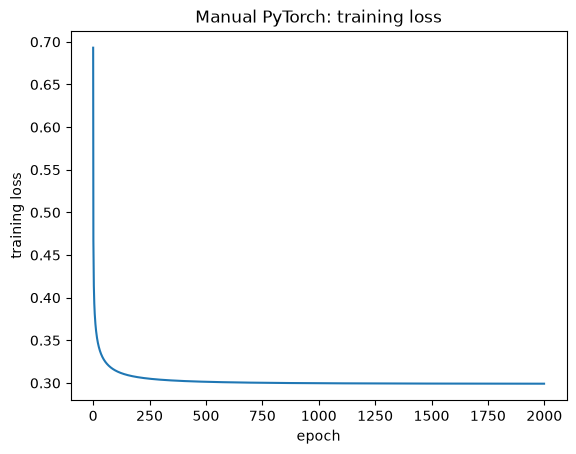

In [19]:
import matplotlib.pyplot as plt

BEST_LR_MANUAL = 1.0
manual_w, manual_b, manual_hist = train_manual(BEST_LR_MANUAL)

# Score it on the validation set and add it to the comparison table
with torch.no_grad():
    manual_val_prob = torch.sigmoid(X_val_t @ manual_w + manual_b).numpy()
results.append(evaluate(y_val, manual_val_prob, "Manual PyTorch"))

# Loss curve: should drop quickly, then flatten out
plt.plot(manual_hist)
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.title("Manual PyTorch: training loss")

pd.DataFrame(results).round(3)

## 18. Model 3: standard PyTorch (nn.Module + torch.optim)
Same logistic regression, built the standard way: nn.Linear holds the weights and bias, nn.BCELoss computes the loss, and the SGD optimizer does the update step. I use plain SGD (the same full-batch gradient descent as the manual model) and add the same L2 penalty, so the comparison isolates the tooling, not the algorithm. I try the same four learning rates on the validation set.

In [20]:
import torch.nn as nn

def train_standard(lr, n_epochs=2000):
    torch.manual_seed(42)                      # nn.Linear starts with random weights; fix them
    model = nn.Sequential(nn.Linear(n_features, 1), nn.Sigmoid())
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    loss_history = []
    for epoch in range(n_epochs):
        optimizer.zero_grad()                                 # reset gradients
        y_pred = model(X_train_t).squeeze(-1)                 # forward pass
        weights = model[0].weight
        loss = loss_fn(y_pred, y_train_t) + L2_STRENGTH / 2 * (weights ** 2).sum()
        loss.backward()                                       # gradients
        optimizer.step()                                      # update
        loss_history.append(loss.item())
    return model, loss_history

for lr in [0.01, 0.1, 0.5, 1.0]:
    model, hist = train_standard(lr)
    with torch.no_grad():
        val_prob = model(X_val_t).squeeze(-1).numpy()
    print(f"lr = {lr:<5}  final train loss = {hist[-1]:.4f}   val log loss = {log_loss(y_val, val_prob):.4f}")

lr = 0.01   final train loss = 0.3499   val log loss = 0.3791
lr = 0.1    final train loss = 0.3069   val log loss = 0.3349
lr = 0.5    final train loss = 0.2997   val log loss = 0.3288
lr = 1.0    final train loss = 0.2992   val log loss = 0.3281


## 19. Final standard PyTorch model (lr = 1.0)
lr = 1.0 again gave the lowest validation log loss (0.328), the same as the manual model and scikit-learn. At small learning rates, the standard model differs slightly from the manual one because nn.Linear starts from random weights instead of zeros; once training converges, both reach the same result.

,model,ROC-AUC,log loss,recall,precision,contacted,missed,cost (€)
0,Naive baseline,0.50,0.669,1.000,0.391,726,0,217800
1,scikit-learn,0.92,0.328,0.915,0.707,368,24,146400
2,Manual PyTorch,0.92,0.328,0.915,0.707,368,24,146400
3,Standard PyTorch,0.92,0.328,0.915,0.707,368,24,146400


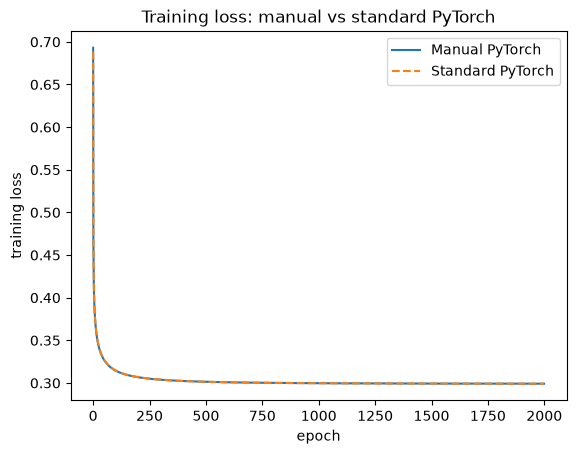

In [21]:
BEST_LR_STANDARD = 1.0
std_model, std_hist = train_standard(BEST_LR_STANDARD)

with torch.no_grad():
    std_val_prob = std_model(X_val_t).squeeze(-1).numpy()
results.append(evaluate(y_val, std_val_prob, "Standard PyTorch"))

plt.plot(manual_hist, label="Manual PyTorch")
plt.plot(std_hist, label="Standard PyTorch", linestyle="--")
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.title("Training loss: manual vs standard PyTorch")
plt.legend()

pd.DataFrame(results).round(3)

## 20. Final evaluation on the test set
All choices (C = 1, lr = 1.0) were made on the validation set. The test set is used only here, once, for the final results. I also compare the learned weights directly: if the three implementations solve the same problem, their weights should match, not just their scores.

In [22]:
X_test_t = torch.tensor(X_test_prep, dtype=torch.float32)

# Each model's dropout probabilities for the test students
with torch.no_grad():
    test_probs = {
        "Naive baseline": np.full(len(y_test), y_train.mean()),
        "scikit-learn": sk_model.predict_proba(X_test_prep)[:, 1],
        "Manual PyTorch": torch.sigmoid(X_test_t @ manual_w + manual_b).numpy(),
        "Standard PyTorch": std_model(X_test_t).squeeze(-1).numpy(),
    }

test_results = pd.DataFrame([evaluate(y_test, prob, name) for name, prob in test_probs.items()])

# Do the three models learn the same weights?
sk_weights = sk_model.coef_[0]
manual_weights = manual_w.detach().numpy()
std_weights = std_model[0].weight.detach().numpy()[0]
print("Largest weight difference, scikit-learn vs manual:  ", np.abs(sk_weights - manual_weights).max().round(4))
print("Largest weight difference, scikit-learn vs standard:", np.abs(sk_weights - std_weights).max().round(4))

test_results.round(3)

Largest weight difference, scikit-learn vs manual:   0.2752
Largest weight difference, scikit-learn vs standard: 0.2977


,model,ROC-AUC,log loss,recall,precision,contacted,missed,cost (€)
0,Naive baseline,0.500,0.669,1.000,0.391,726,0,217800
1,scikit-learn,0.929,0.326,0.933,0.659,402,19,149100
2,Manual PyTorch,0.929,0.326,0.937,0.660,403,18,147900
3,Standard PyTorch,0.929,0.326,0.937,0.660,403,18,147900


## 21. Why do the weights differ when the predictions match
The predictions agree, but individual weights differ by up to 0.28. I check which features have the biggest differences: if they are one-hot category columns, the gap comes from redundancy in the encoding (each category group always sums to 1, which overlaps with the intercept), not from a mistake in the models.

In [23]:
weight_gap = pd.Series(np.abs(sk_weights - manual_weights), index=feature_names)
print(weight_gap.sort_values(ascending=False).head(10).round(3))

yes_no__passed_nothing_1st_sem                        0.275
categories__Course_infrequent_sklearn                 0.200
yes_no__no_units_1st_sem                              0.168
categories__Course_171                                0.166
categories__Father's occupation_0                     0.145
categories__Father's occupation_infrequent_sklearn    0.135
categories__Mother's occupation_infrequent_sklearn    0.104
categories__Mother's occupation_0                     0.082
categories__Mother's qualification_34                 0.077
numbers__Curricular units 1st sem (grade)             0.074
dtype: float64


## 22. Confirming the explanation
The largest weight gaps are in overlapping features, such as rare category columns, and passed_nothing and no_units overlap with pass rate, approved units and grade. This collinearity makes the loss almost flat in some directions, so gradient descent settles those weights slowly. If that is the cause, training 10x longer should shrink the gap.

In [24]:
long_w, long_b, _ = train_manual(BEST_LR_MANUAL, n_epochs=20000)
long_gap = np.abs(sk_weights - long_w.detach().numpy()).max()

print("Largest weight gap after  2,000 epochs:", weight_gap.max().round(3))
print("Largest weight gap after 20,000 epochs:", long_gap.round(3))

Largest weight gap after  2,000 epochs: 0.275
Largest weight gap after 20,000 epochs: 0.061


## 23. Ablation check
Same scikit-learn model, same split, same preprocessing, only the extra columns (Gender, and the fees columns: Debtor, and the payments of to date. Compared on the validation set.

In [25]:
extra_data = pd.concat([fees, gender], axis=1)

def run_variant(extra_cols, name):
    # Add the extra columns back to the same train/validation students
    X_tr = X_train.join(extra_data[extra_cols])
    X_va = X_val.join(extra_data[extra_cols])
    prep = ColumnTransformer([
        ("categories", OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist",
                                     sparse_output=False), category_cols),
        ("numbers", StandardScaler(), numeric_cols),
        ("yes_no", "passthrough", binary_cols + extra_cols),
    ])
    X_tr_p = prep.fit_transform(X_tr)
    X_va_p = prep.transform(X_va)
    model = LogisticRegression(C=BEST_C, max_iter=1000).fit(X_tr_p, y_train)
    return evaluate(y_val, model.predict_proba(X_va_p)[:, 1], name)

ablation = pd.DataFrame([
    run_variant([], "Main model"),
    run_variant(["Debtor", "Tuition fees up to date"], "+ fee columns"),
    run_variant(["Gender"], "+ Gender"),
    run_variant(["Debtor", "Tuition fees up to date", "Gender"], "+ fees and Gender"),
])
ablation.round(3)

,model,ROC-AUC,log loss,recall,precision,contacted,missed,cost (€)
0,Main model,0.920,0.328,0.915,0.707,368,24,146400
1,+ fee columns,0.934,0.294,0.908,0.744,347,26,143100
2,+ Gender,0.921,0.325,0.915,0.701,371,24,147300
3,+ fees and Gender,0.935,0.290,0.915,0.749,347,24,140100


Adding Gender changed almost nothing (ROC-AUC +0.001, cost +€900), so excluding it for fairness had no measurable cost. Adding the fee columns improved the model moderately (ROC-AUC 0.920 to 0.934, cost −€3,300), but because their recording time is unknown, I kept them out. If a student stopped paying after they dropped out it could have been recorded as payments not up to date.

## 24. Fairness check to see if the the model works equally well for men and women
Gender is not a model input, but other features could still act as stand-ins for it. I compare recall and precision for each group on the test set.

In [26]:
test_gender = gender.loc[X_test.index, "Gender"].values
sk_test_pred = (test_probs["scikit-learn"] >= THRESHOLD).astype(int)

for value, label in [(0, "Female"), (1, "Male")]:
    mask = test_gender == value
    rec = recall_score(y_test[mask], sk_test_pred[mask])
    prec = precision_score(y_test[mask], sk_test_pred[mask])
    print(f"{label}: {mask.sum()} students   recall = {rec:.3f}   precision = {prec:.3f}")

Female: 438 students   recall = 0.923   precision = 0.588
Male: 288 students   recall = 0.942   precision = 0.732


Recall is similar for women (0.923) and men (0.942), so the model catches dropouts about equally well in both groups. Precision is lower for women (0.588 vs 0.732), meaning more women are contacted who would not have dropped out. This mainly reflects their lower dropout rate (30% vs 56%). An extra support offer is low-harm for the student but adds cost for the university.

## 25. Save artifacts for the dashboard
The dashboard must not retrain anything, so I save the three trained models, the fitted preprocessor, the test data and the settings to an artifacts/ folder. app.ipynb loads them from there.

In [27]:
import joblib
from pathlib import Path

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)   # create the folder if it doesn't exist

# 1. The three trained models
joblib.dump(sk_model, ARTIFACTS / "sklearn_model.joblib")
torch.save({"w": manual_w.detach(), "b": manual_b.detach()}, ARTIFACTS / "manual_pytorch.pt")
torch.save(std_model.state_dict(), ARTIFACTS / "standard_pytorch.pt")

# 2. The fitted preprocessor, so new data is prepared exactly like the training data
joblib.dump(preprocessor, ARTIFACTS / "preprocessor.joblib")

# 3. Data and settings the dashboard needs
joblib.dump({
    "X_test": X_test,
    "y_test": y_test,
    "clean_data": df,
    "n_features": n_features,
    "cost_contact": COST_CONTACT,
    "cost_missed": COST_MISSED,
    "threshold": THRESHOLD,
    "test_results": test_results,
}, ARTIFACTS / "dashboard_data.joblib")

print(sorted(p.name for p in ARTIFACTS.iterdir()))

['dashboard_data.joblib', 'manual_pytorch.pt', 'preprocessor.joblib', 'sklearn_model.joblib', 'standard_pytorch.pt']
